## Viscosity manipulation (Danionella, 4wpf)

Analysis of freely swimming in control (water) and high viscosty (dextran, 10x) medium. Only Danionella 4wpf were exposed to high viscosity.

Statistics of swimming duration and maximum speed at the onset of the movement.

Figures are saved to the project `figures/` directory and to `manipulation_experiments/media/`.

Import libraries:

In [38]:
# --- Imports and path setup (paths from code/paths.py) ---
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import FIGURES_DIR, DATA_VISCOSITY, notebook_media_dir
path_media = str(notebook_media_dir("manipulation_experiments"))

%load_ext autoreload
%autoreload 2
from functions.freely_swimming import *
from functions.MC_freely_swimming import *
from collections import defaultdict

import os
import h5py
from ipywidgets import interact, IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


#### Import data:

In [2]:
# Setup
exp_step = 'pre'
path = str(DATA_VISCOSITY)
path_pre = os.path.join(path, exp_step)
print("Looking in:", path_pre)

for file in os.listdir(path_pre):
    print(file)
    
fish_id = 'fs_31dpf_12Apr25_1'

Looking in: <repo>/data/manipulation_experiments/viscosity/pre
fs_31dpf_12Apr25_3_1
.DS_Store
fs_31dpf_12Apr25_2_3
fs_31dpf_27Mar25_2_3
fs_31dpf_12Apr25_1_1
fs_31dpf_27Mar25_1_1


In [3]:
c_binary_all_runs = []
c_t_c_all_runs = []
c_dangletail_c_all_runs = []
c_freqtail_c_all_runs = []
c_vtail_c_all_runs = []

c_tvals_all_runs = []
c_theta_all_runs = []
c_vfish_c_all_runs = []

c_mask_movetail_all_runs = []

        
for file in os.listdir(path_pre):
    if file[:-2] == fish_id:
        print(file)
        
        aux = os.path.join(path_pre, file)
        hdf5_file = h5py.File(aux, "r")

        binary = hdf5_file['post-processing/binary_output'][:]
        t_c = hdf5_file['post-processing/t_c'][:]
        dangletail_c = hdf5_file['post-processing/dtheta_c'][:]
        freqtail_c = hdf5_file['post-processing/freqtail_c'][:]
        vtail_c = hdf5_file['post-processing/vtail_c'][:]

        tvals = hdf5_file['post-processing/tvals'][:]
        theta = hdf5_file['post-processing/theta'][:]
        speed_smooth = hdf5_file['post-processing/speed_smooth'][:]
        f_c=interp1d(tvals,speed_smooth,fill_value='extrapolate')
        vfish_c = f_c(t_c)

        hdf5_file.close()

        # Append to your _all_runs lists
        c_binary_all_runs.append(binary)
        c_t_c_all_runs.append(t_c)
        c_dangletail_c_all_runs.append(dangletail_c)
        c_freqtail_c_all_runs.append(freqtail_c)
        c_vtail_c_all_runs.append(vtail_c)

        c_tvals_all_runs.append(tvals)
        c_theta_all_runs.append(theta)
        c_vfish_c_all_runs.append(vfish_c)

        c_mask_movetail_all_runs.append(binary.astype(bool))


fs_31dpf_12Apr25_1_1


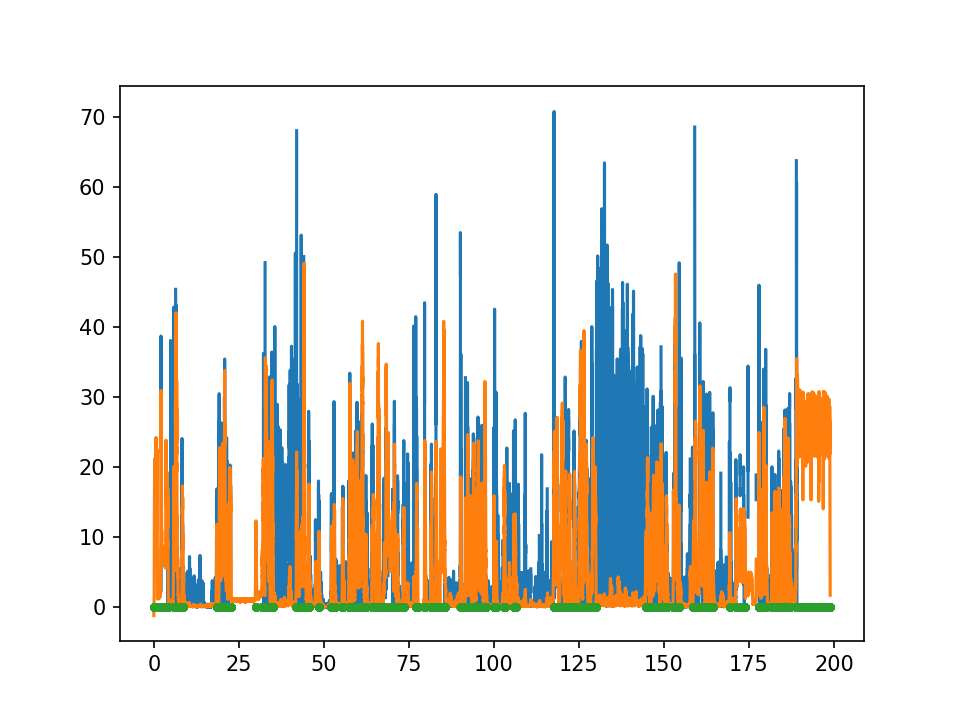

In [4]:
id_run = 0


default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.plot(c_t_c_all_runs[id_run],c_vtail_c_all_runs[id_run]/10,'-')
ax.plot(c_t_c_all_runs[id_run],c_vfish_c_all_runs[id_run],'-')
ax.plot(c_tvals_all_runs[id_run][c_mask_movetail_all_runs[id_run]], np.zeros(np.sum(c_mask_movetail_all_runs[id_run])),'.')

#ax.set_xlim(255,255.5)
plt.show()

In [5]:
tau_on_all_runs_control = []
tau_off_all_runs_control = []
for i in range(len(c_mask_movetail_all_runs)):
    tau_on, tau_off = compute_tau_on_off(c_mask_movetail_all_runs[i])
    tau_on_all_runs_control.append(tau_on)
    tau_off_all_runs_control.append(tau_off)
    
tau_on_all_runs_control = np.concatenate(tau_on_all_runs_control)

0.24833333333333335


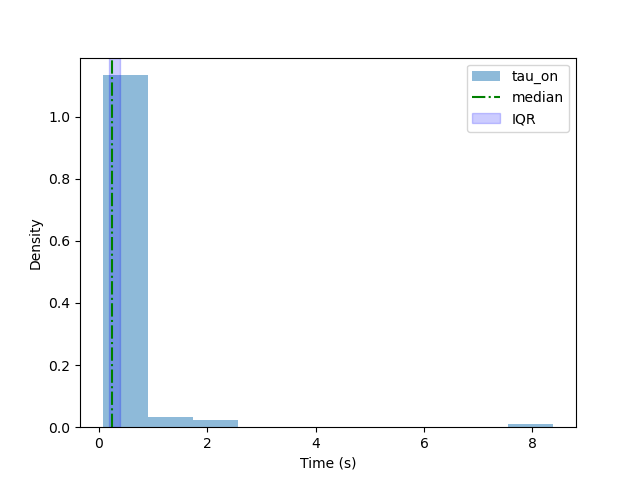

In [6]:
plt.figure()
plt.hist(tau_on_all_runs_control, bins=10, density=True, alpha=0.5, label='tau_on')
#plt.axvline(np.mean(tau_on), color='r', linestyle='--', label='mean')
plt.axvline(np.median(tau_on_all_runs_control), color='g', linestyle='-.', label='median')
q1, q3 = np.percentile(tau_on_all_runs_control, [25, 75])
plt.axvspan(q1, q3, color='b', alpha=0.2, label='IQR')
#plt.hist(tau_off, bins=100, density=True, alpha=0.5, label='tau_off')
plt.xlabel('Time (s)')
plt.ylabel('Density')
#plt.xlim(0,1)
plt.legend()
print(np.median(tau_on_all_runs_control))
plt.show()

#### Import data:

In [7]:
# Setup
exp_step = 'dextran'
path = str(DATA_VISCOSITY)
path_pre = os.path.join(path, exp_step)
print("Looking in:", path_pre)

Looking in: <repo>/data/manipulation_experiments/viscosity/dextran


In [8]:
v_binary_all_runs = []
v_t_c_all_runs = []
v_dangletail_c_all_runs = []
v_freqtail_c_all_runs = []
v_vtail_c_all_runs = []

v_tvals_all_runs = []
v_theta_all_runs = []
v_vfish_c_all_runs = []

v_mask_movetail_all_runs = []

        
for file in os.listdir(path_pre):
    if file[:-2] == fish_id:
        print(file)
        
        aux = os.path.join(path_pre, file)
        hdf5_file = h5py.File(aux, "r")

        binary = hdf5_file['post-processing/binary_output'][:]
        t_c = hdf5_file['post-processing/t_c'][:]
        dangletail_c = hdf5_file['post-processing/dtheta_c'][:]
        freqtail_c = hdf5_file['post-processing/freqtail_c'][:]
        vtail_c = hdf5_file['post-processing/vtail_c'][:]

        tvals = hdf5_file['post-processing/tvals'][:]
        theta = hdf5_file['post-processing/theta'][:]
        speed_smooth = hdf5_file['post-processing/speed_smooth'][:]
        f_c=interp1d(tvals,speed_smooth,fill_value='extrapolate')
        vfish_c = f_c(t_c)

        hdf5_file.close()

        # Append to your _all_runs lists
        v_binary_all_runs.append(binary)
        v_t_c_all_runs.append(t_c)
        v_dangletail_c_all_runs.append(dangletail_c)
        v_freqtail_c_all_runs.append(freqtail_c)
        v_vtail_c_all_runs.append(vtail_c)

        v_tvals_all_runs.append(tvals)
        v_theta_all_runs.append(theta)
        v_vfish_c_all_runs.append(vfish_c)

        v_mask_movetail_all_runs.append(binary.astype(bool))


fs_31dpf_12Apr25_1_4
fs_31dpf_12Apr25_1_3
fs_31dpf_12Apr25_1_2
fs_31dpf_12Apr25_1_5
fs_31dpf_12Apr25_1_6
fs_31dpf_12Apr25_1_1


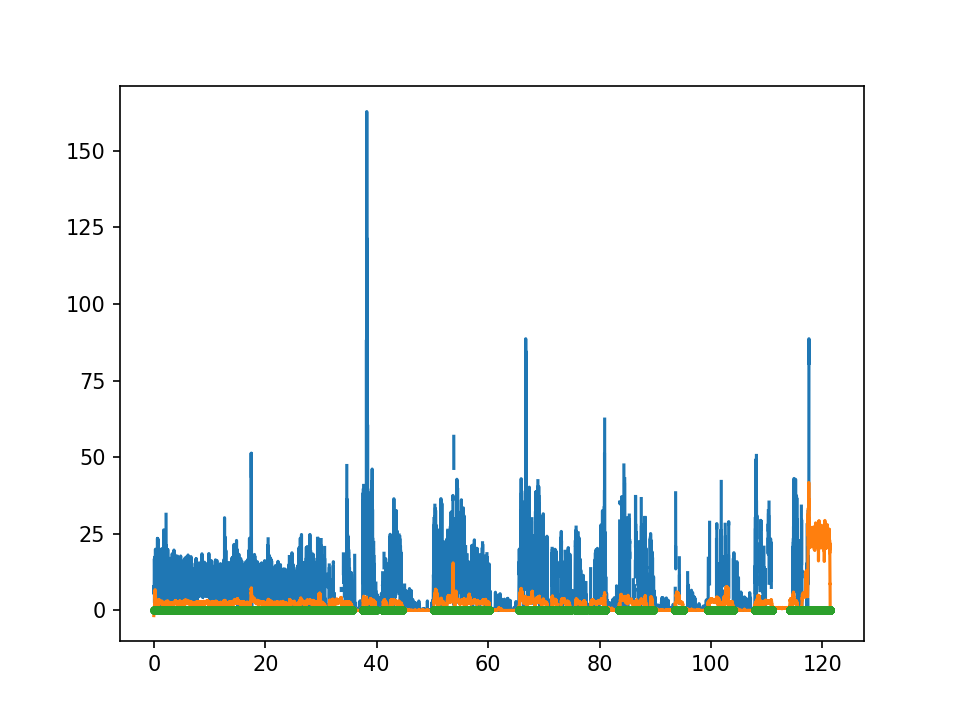

In [9]:
dt=1/300

id_run = 1

default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.plot(v_t_c_all_runs[id_run],v_vtail_c_all_runs[id_run]/10,'-')
ax.plot(v_t_c_all_runs[id_run],v_vfish_c_all_runs[id_run],'-')
ax.plot(v_tvals_all_runs[id_run][v_mask_movetail_all_runs[id_run]], np.zeros(np.sum(v_mask_movetail_all_runs[id_run])),'.')

#ax.set_xlim(255,255.5)
plt.show()

In [10]:
tau_on_all_runs_viscosity = []
tau_off_all_runs_viscosity = []
for i in range(len(v_mask_movetail_all_runs)):
    tau_on, tau_off = compute_tau_on_off(v_mask_movetail_all_runs[i])
    tau_on_all_runs_viscosity.append(tau_on)
    tau_off_all_runs_viscosity.append(tau_off)
    
tau_on_all_runs_viscosity = np.concatenate(tau_on_all_runs_viscosity)

1.2166666666666668


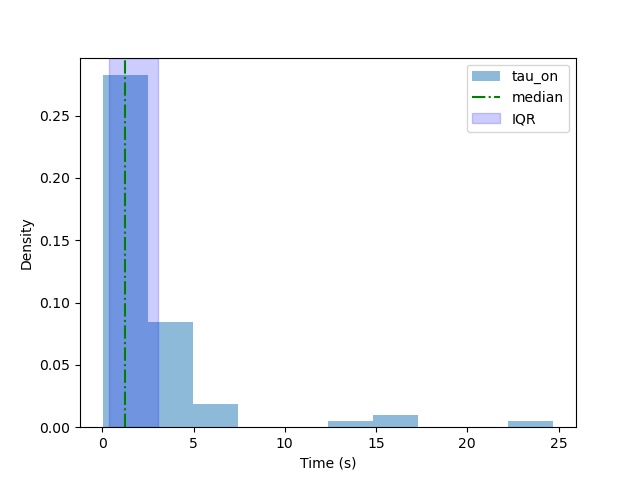

In [11]:
plt.figure()
plt.hist(tau_on_all_runs_viscosity, bins=10, density=True, alpha=0.5, label='tau_on')
#plt.axvline(np.mean(tau_on), color='r', linestyle='--', label='mean')
plt.axvline(np.median(tau_on_all_runs_viscosity), color='g', linestyle='-.', label='median')
q1, q3 = np.percentile(tau_on_all_runs_viscosity, [25, 75])
plt.axvspan(q1, q3, color='b', alpha=0.2, label='IQR')
#plt.hist(tau_off, bins=100, density=True, alpha=0.5, label='tau_off')
plt.xlabel('Time (s)')
plt.ylabel('Density')
#plt.xlim(0,1)
plt.legend()
print(np.median(tau_on_all_runs_viscosity))
plt.show()

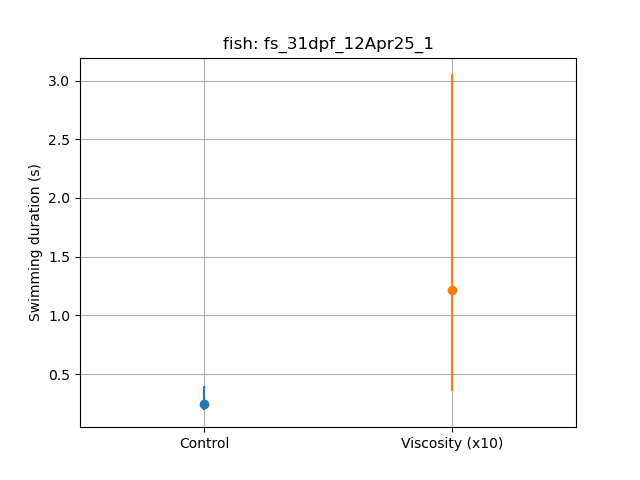

In [12]:
summary_swimming_durations = []

# Example: one fish
n_fish = 1

plt.figure()

# --- Control condition ---
y = tau_on_all_runs_control  # 1D array
median_control = np.median(y)
q1_control, q3_control = np.percentile(y, [25, 75])
iqr_control = [[median_control - q1_control], [q3_control - median_control]]
plt.errorbar(0, median_control, yerr=iqr_control, fmt='o')

# --- Viscosity condition ---
y = tau_on_all_runs_viscosity  # 1D array
median_visc = np.median(y)
q1_visc, q3_visc = np.percentile(y, [25, 75])
iqr_visc = [[median_visc - q1_visc], [q3_visc - median_visc]]
plt.errorbar(1, median_visc, yerr=iqr_visc, fmt='o')

# Plot formatting
plt.xlim(-0.5, 1.5)
plt.xticks([0, 1], ['Control', 'Viscosity (x10)'])
plt.ylabel('Swimming duration (s)')
plt.title(f'fish: {fish_id}')
plt.grid(True)
plt.show()

# --- Save summary ---
summary_swimming_durations.append({
    'fish_id': fish_id,
    'median_control': median_control,
    'iqr_control': (q1_control, q3_control),
    'median_viscosity': median_visc,
    'iqr_viscosity': (q1_visc, q3_visc)
})

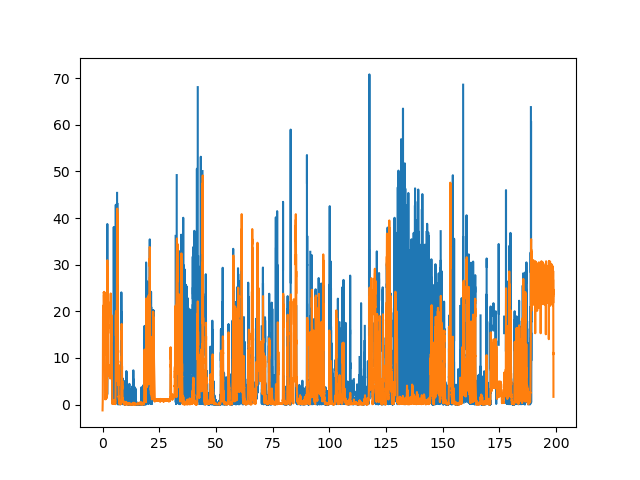

In [13]:
id_run = 0


default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=100)
ax.plot(c_t_c_all_runs[id_run],c_vtail_c_all_runs[id_run]/10,'-', label='vtail / 10')
ax.plot(c_t_c_all_runs[id_run],c_vfish_c_all_runs[id_run],'-', label='vfish')

#ax.set_xlim(57,61)
#ax.set_ylim(-1,50)
plt.show()

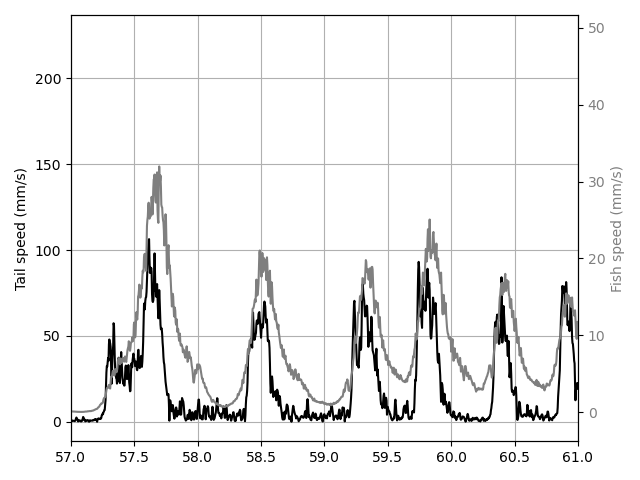

In [14]:
id_run = 0

fig, ax1 = plt.subplots(figsize=(6.4, 4.8), dpi=100)

# --- Left y-axis: vtail / 10 ---
ax1.plot(c_t_c_all_runs[id_run], c_vtail_c_all_runs[id_run] / np.pi, '-', color='black', label='vtail / 10')
ax1.set_ylabel('Tail speed (mm/s)')
ax1.tick_params(axis='y')
ax1.set_xlim(57, 61)
#ax1.set_ylim(-1, 100)

# --- Right y-axis: vfish ---
ax2 = ax1.twinx()
ax2.plot(c_t_c_all_runs[id_run], c_vfish_c_all_runs[id_run], '-', color='tab:gray', label='vfish')
ax2.set_ylabel('Fish speed (mm/s)', color='tab:gray')
ax2.tick_params(axis='y', labelcolor='tab:gray')
ax2.set_xlim(57, 61)
#ax2.set_ylim(-1, 50)

# --- Title and grid ---
ax1.grid(True)


plt.tight_layout()
plt.show()

In [15]:
np.nanmedian(c_vfish_c_all_runs[id_run])

1.2753540832382506

In [16]:
np.nanmedian(c_vtail_c_all_runs[id_run])

15.317334922253202

In [17]:
15/(np.pi * 1.3)

3.6728063790437386

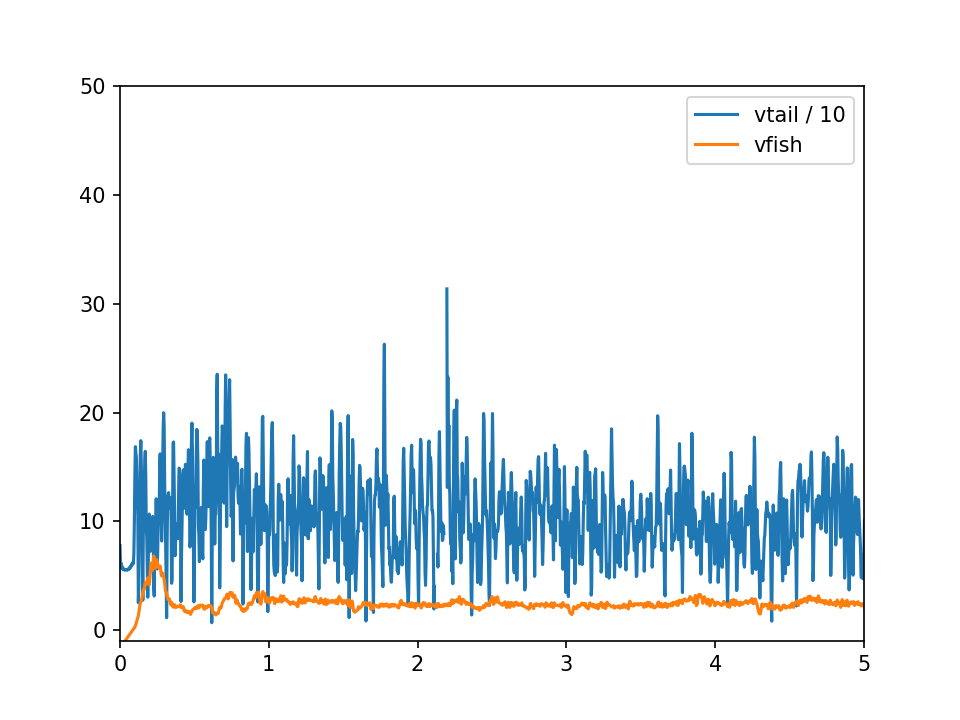

In [18]:
id_run = 1

default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.plot(v_t_c_all_runs[id_run],v_vtail_c_all_runs[id_run]/10,'-', label='vtail / 10')
ax.plot(v_t_c_all_runs[id_run],v_vfish_c_all_runs[id_run],'-', label='vfish')
#ax.plot(v_tvals_all_runs[id_run][v_mask_movetail_all_runs[id_run]], np.zeros(np.sum(v_mask_movetail_all_runs[id_run])),'.')

ax.set_xlim(0,5)
ax.set_ylim(-1,50)

plt.legend()
plt.show()

In [19]:
np.nanmedian(v_vfish_c_all_runs[id_run])

2.3188335949758385

In [20]:
np.nanmedian(v_vtail_c_all_runs[id_run])

65.78611699851092

In [21]:
np.nanmedian(v_vtail_c_all_runs[id_run]) / (np.pi * np.nanmedian(v_vfish_c_all_runs[id_run]))

9.030562373962734

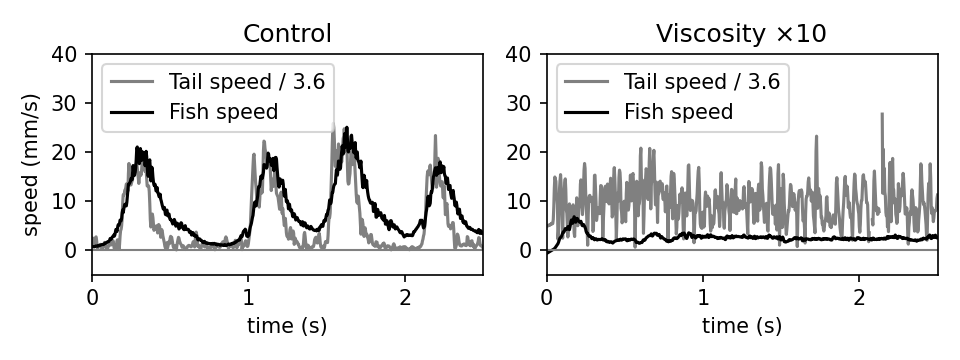

In [22]:
default()
widget()
fig, axs = plt.subplots(1, 2, figsize=(6.4,4.8/2),dpi=150)

# --- CONTROL ---
id_run = 0
ax = axs[0]

ax.plot(c_t_c_all_runs[id_run]-58.2, c_vtail_c_all_runs[id_run] / (np.pi * 3.6), color='gray', label='Tail speed / 3.6')
ax.plot(c_t_c_all_runs[id_run]-58.2, c_vfish_c_all_runs[id_run], color='k', label='Fish speed')
ax.axhline(0, color='gray', linestyle='-', linewidth=1)
ax.set_title("Control")
ax.set_xlim(0, 2.5)
ax.set_xticks([0, 1, 2]) 
ax.set_ylim(-5, 40)
ax.set_ylabel("speed (mm/s)")
ax.set_xlabel("time (s)")

ax.legend()

# --- VISCOSITY ---
id_run = 1
ax = axs[1]

ax.plot(v_t_c_all_runs[id_run]-0.05, v_vtail_c_all_runs[id_run] / (np.pi * 3.6), color='gray', label='Tail speed / 3.6')
ax.plot(v_t_c_all_runs[id_run]-0.05, v_vfish_c_all_runs[id_run], color='k', label='Fish speed')
ax.axhline(0, color='gray', linestyle='-', linewidth=1)
ax.set_title("Viscosity ×10")
ax.set_xlim(0, 2.5)
ax.set_xticks([0, 1, 2]) 
ax.set_ylim(-5, 40)

ax.set_xlabel("time (s)")
ax.legend()

plt.tight_layout()
plt.show()

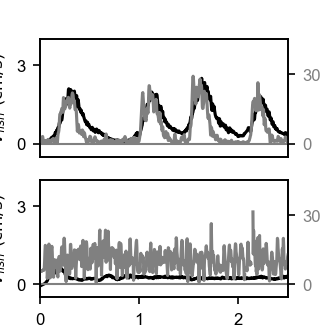

In [23]:
default()
widget()
arial()
#fig, axs = plt.subplots(2, 1, figsize=(6.4, 4.8), dpi=150)
cm_to_inch = 1 / 2.54
fig_width_cm = 5
fig_height_cm = 5

#fig, axs = plt.subplots(2, 1,   figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),    dpi=50)
fig, axs = plt.subplots(2, 1, figsize=(6.4/2/1.5, 4.8/2.2+0.05), dpi=150)
# --- Define consistent range in cm/s ---
ymin = -0.5
ymax = 4.0
tail_scale = np.pi * 3.6  # scaling factor that was previously applied

# === CONTROL CONDITION ===
id_run = 0
ax1 = axs[0]
ax2 = ax1.twinx()

# Main y-axis (left): Fish speed
ax1.plot(c_t_c_all_runs[id_run] - 58.2, c_vfish_c_all_runs[id_run] / 10, color='black', label='Fish speed')
ax1.set_ylabel(r'$V_{fish}\ (\mathrm{cm/s})$', color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.set_xlim(0, 2.5)
ax1.set_ylim(ymin, ymax)
ax1.set_yticks([0, 3])
ax1.set_xticks([])
ax1.set_xlabel("") 
ax1.axhline(0, color='gray', linestyle='-', linewidth=1)

# Secondary y-axis (right): Tail speed
ax2.plot(c_t_c_all_runs[id_run] - 58.2, c_vtail_c_all_runs[id_run] / 10, color='gray', label='Tail speed')
ax2.set_ylabel(r'$V_{tail}\ (\mathrm{cm/s})$', color='gray')
ax2.set_yticks([0, 30])
ax2.tick_params(axis='y', labelcolor='gray')
ax2.set_ylim(ymin * tail_scale, ymax * tail_scale)  # scaled limits to match visual zero

# === VISCOSITY CONDITION ===
id_run = 1
ax3 = axs[1]
ax4 = ax3.twinx()

# Main y-axis (left): Fish speed
ax3.plot(v_t_c_all_runs[id_run] - 0.05, v_vfish_c_all_runs[id_run] / 10, color='black', label='Fish speed')
ax3.set_ylabel(r'$V_{fish}\ (\mathrm{cm/s})$', color='black')
ax3.tick_params(axis='y', labelcolor='black')
ax3.set_xlim(0, 2.5)
ax3.set_ylim(ymin, ymax)
ax3.set_yticks([0, 3])
ax3.set_xticks([0, 1, 2])
ax3.set_xlabel("time (s)")
ax3.axhline(0, color='gray', linestyle='-', linewidth=1)

# Secondary y-axis (right): Tail speed
ax4.plot(v_t_c_all_runs[id_run] - 0.05, v_vtail_c_all_runs[id_run] / 10, color='gray', label='Tail speed')
ax4.set_ylabel(r'$V_{tail}\ (\mathrm{cm/s})$', color='gray')
ax4.tick_params(axis='y', labelcolor='gray')
ax4.set_yticks([0, 30])
ax4.set_ylim(ymin * tail_scale, ymax * tail_scale)

# --- Final layout ---
#plt.tight_layout()
#fig.savefig(str(FIGURES_DIR / "one_fish_speed_control_viscosity.pdf"), format="pdf")
plt.show()

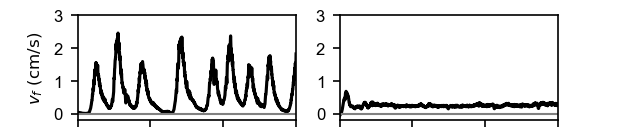

In [24]:
default()
widget()
arial()
#fig, axs = plt.subplots(2, 1, figsize=(6.4, 4.8), dpi=150)
cm_to_inch = 1 / 2.54
fig_width_cm = 10.5
fig_height_cm = 2.3

fig, axs = plt.subplots(1, 2,   figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),    dpi=150)

# --- Define consistent range in cm/s ---
ymin = -0.2
ymax = 2.5
tail_scale = np.pi * 3.6  # scaling factor that was previously applied

# === CONTROL CONDITION ===
id_run = 0
ax1 = axs[0]


# Main y-axis (left): Fish speed
ax1.plot(c_t_c_all_runs[id_run] - 91.2, c_vfish_c_all_runs[id_run] / 10, color='black', label='Fish speed')
ax1.set_ylabel(r'$v_{f}\ (\mathrm{cm/s})$', color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.set_xlim(0, 6)
ax1.set_ylim(ymin, 3)
ax1.set_yticks([0, 1, 2, 3])
#ax1.set_xticks([])
#ax1.set_xlabel("") 
#ax1.set_xticks([0, 1, 2])
ax1.set_xlabel("time (s)")
ax1.axhline(0, color='gray', linestyle='-', linewidth=1)


# === VISCOSITY CONDITION ===
id_run = 1
ax3 = axs[1]


# Main y-axis (left): Fish speed
ax3.plot(v_t_c_all_runs[id_run] - 0.05, v_vfish_c_all_runs[id_run] / 10, color='black', label='Fish speed')
#ax3.set_ylabel(r'$v_{f}\ (\mathrm{cm/s})$', color='black')
ax3.tick_params(axis='y', labelcolor='black')
ax3.set_xlim(0, 6)
ax3.set_ylim(ymin, 3)
ax3.set_yticks([0.0, 1.0, 2.0, 3.0])
ax3.set_xlabel("time (s)")
ax3.axhline(0, color='gray', linestyle='-', linewidth=1)


# --- Final layout ---
#plt.tight_layout()
fig.savefig(str(FIGURES_DIR / "FigS13b_one_fish_speed_control_viscosity_6s.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "FigS13b_one_fish_speed_control_viscosity_6s.pdf"), format="pdf", bbox_inches='tight', dpi=200)
plt.show()

# LOOP all fish - bout duration

In [25]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import matplotlib.cm as cm
from scipy.stats import mannwhitneyu

summary_swimming_durations = []

def load_fish_data(path_step, fish_id):
    all_runs = {
        'binary': [], 't_c': [], 'dangletail_c': [], 'freqtail_c': [], 'vtail_c': [],
        'tvals': [], 'theta': [], 'vfish_c': [], 'mask_movetail': []
    }
    
    for file in os.listdir(path_step):
        if file.startswith(fish_id + '_'):
            file_path = os.path.join(path_step, file)
            if not os.path.isfile(file_path):  # skip folders or non-HDF5 content
                continue
            try:
                with h5py.File(file_path, "r") as hdf5_file:
                    binary = hdf5_file['post-processing/binary_output'][:]
                    t_c = hdf5_file['post-processing/t_c'][:]
                    dangletail_c = hdf5_file['post-processing/dtheta_c'][:]
                    freqtail_c = hdf5_file['post-processing/freqtail_c'][:]
                    vtail_c = hdf5_file['post-processing/vtail_c'][:]
                    tvals = hdf5_file['post-processing/tvals'][:]
                    theta = hdf5_file['post-processing/theta'][:]
                    speed_smooth = hdf5_file['post-processing/speed_smooth'][:]
                    f_c = interp1d(tvals, speed_smooth, fill_value='extrapolate')
                    vfish_c = f_c(t_c)
            except Exception as e:
                print(f"⚠️ Could not read {file}: {e}")
                continue

            all_runs['binary'].append(binary)
            all_runs['t_c'].append(t_c)
            all_runs['dangletail_c'].append(dangletail_c)
            all_runs['freqtail_c'].append(freqtail_c)
            all_runs['vtail_c'].append(vtail_c)
            all_runs['tvals'].append(tvals)
            all_runs['theta'].append(theta)
            all_runs['vfish_c'].append(vfish_c)
            all_runs['mask_movetail'].append(binary.astype(bool))
    
    return all_runs

def compute_all_tau(mask_list):
    tau_on_all, tau_off_all = [], []
    for mask in mask_list:
        if mask is not None and np.any(mask):  # Skip empty or all-False masks
            tau_on, tau_off = compute_tau_on_off(mask)
            tau_on_all.append(tau_on)
            tau_off_all.append(tau_off)
    if len(tau_on_all) == 0:
        return np.array([]), np.array([])
    return np.concatenate(tau_on_all), np.concatenate(tau_off_all)

# List all fish_ids by stripping the suffix from filename
def extract_fish_ids(path):
    fish_ids = set()
    for file in os.listdir(path):
        if file.startswith('fs_') and not file.startswith('.'):
            parts = file.split('_')
            if parts[-1].isdigit():
                fish_id = '_'.join(parts[:-1])  # drop ONLY the last part
                fish_ids.add(fish_id)
    return sorted(fish_ids)

# Paths
root_path = str(DATA_VISCOSITY)
path_control = os.path.join(root_path, 'pre')
path_viscosity = os.path.join(root_path, 'dextran')

# Extract all fish IDs present in both folders
fish_ids = list(set(extract_fish_ids(path_control)) & set(extract_fish_ids(path_viscosity)))
print(f"Found {len(fish_ids)} fish:", fish_ids)

# Loop over all fish
for i, fish_id in enumerate(fish_ids):
    print(f"\nProcessing {fish_id} ({i+1}/{len(fish_ids)})")
    print(fish_id)
    # Load data
    control_data = load_fish_data(path_control, fish_id)
    viscosity_data = load_fish_data(path_viscosity, fish_id)
    
    # Compute τ_on for control and viscosity
    tau_on_control, _ = compute_all_tau(control_data['mask_movetail'])
    tau_on_viscosity, _ = compute_all_tau(viscosity_data['mask_movetail'])
    # Compute statistical test between the two distributions
    try:
        stat, pval = mannwhitneyu(tau_on_control, tau_on_viscosity, alternative='two-sided')
    except ValueError:
        stat, pval = np.nan, np.nan

    # Skip fish if either array is empty
    if tau_on_control.size == 0 or tau_on_viscosity.size == 0:
        print(f"⚠️ Skipping {fish_id} — empty τ_on array(s)")
        continue

    # Compute stats
    median_control = np.median(tau_on_control)
    q1_control, q3_control = np.percentile(tau_on_control, [25, 75])

    median_visc = np.median(tau_on_viscosity)
    q1_visc, q3_visc = np.percentile(tau_on_viscosity, [25, 75])
    
    mean_control = np.mean(tau_on_control)
    std_control = np.std(tau_on_control)

    mean_viscosity = np.mean(tau_on_viscosity)
    std_viscosity = np.std(tau_on_viscosity)
        
    # Store summary
    summary_swimming_durations.append({
        'fish_id': fish_id,
        'median_control': median_control,
        'iqr_control': (q1_control, q3_control),
        'mean_control': mean_control,
        'std_control': std_control,
        'tau_on_control': tau_on_control,
        'median_viscosity': median_visc,
        'iqr_viscosity': (q1_visc, q3_visc),
        'mean_viscosity': mean_viscosity,
        'std_viscosity': std_viscosity,
        'tau_on_viscosity': tau_on_viscosity,
        'p_value': pval
        
    })

Found 5 fish: ['fs_31dpf_12Apr25_3', 'fs_31dpf_12Apr25_1', 'fs_31dpf_27Mar25_1', 'fs_31dpf_12Apr25_2', 'fs_31dpf_27Mar25_2']

Processing fs_31dpf_12Apr25_3 (1/5)
fs_31dpf_12Apr25_3

Processing fs_31dpf_12Apr25_1 (2/5)
fs_31dpf_12Apr25_1

Processing fs_31dpf_27Mar25_1 (3/5)
fs_31dpf_27Mar25_1

Processing fs_31dpf_12Apr25_2 (4/5)
fs_31dpf_12Apr25_2

Processing fs_31dpf_27Mar25_2 (5/5)
fs_31dpf_27Mar25_2


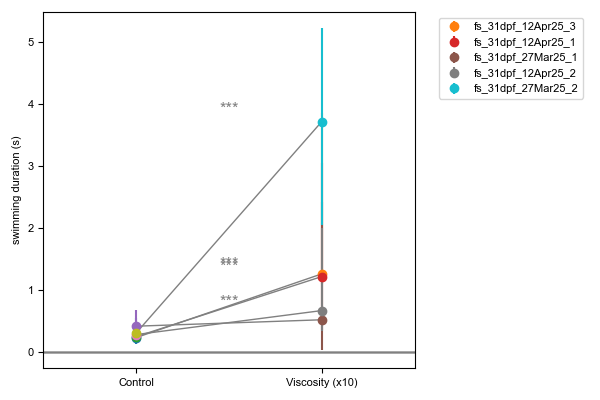

In [26]:
color = 'gray'
plt.figure(figsize=(6, 4))

for i, summary in enumerate(summary_swimming_durations):
    #color = colors[i]
    y_control = summary['median_control']
    y_visc = summary['median_viscosity']
    plt.axhline(0, color='gray', linestyle='-', linewidth=1)

    # Error bars
    plt.errorbar(0, y_control,
                 yerr=[[y_control - summary['iqr_control'][0]],
                       [summary['iqr_control'][1] - y_control]],
                 fmt='o')
    
    plt.errorbar(1, y_visc,
                 yerr=[[y_visc - summary['iqr_viscosity'][0]],
                       [summary['iqr_viscosity'][1] - y_visc]],
                 fmt='o', label=summary['fish_id'])
    
    # Line connecting the two
    plt.plot([0, 1], [y_control, y_visc], color=color, linewidth=1)
    
    # Add significance star
    p = summary.get('p_value', np.nan)
    if not np.isnan(p):
        if p < 0.001:
            star = '***'
        elif p < 0.01:
            star = '**'
        elif p < 0.05:
            star = '*'
        else:
            star = ''
        if star:
            y_star = max(y_control, y_visc) + 0.02 * max(y_control, y_visc)  # slightly above higher point
            plt.text(0.5, y_star, star, ha='center', va='bottom', color=color, fontsize=12)

plt.xlim(-0.5, 1.5)
plt.xticks([0, 1], ['Control', 'Viscosity (x10)'])
plt.ylabel('swimming duration (s)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
#plt.grid(True)
plt.tight_layout()
plt.show()

p-value: 2.419e-21


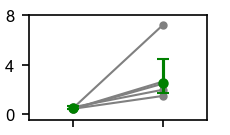

In [32]:
default()
widget()
arial()

# --- Figure settings ---
cm_to_inch = 1 / 2.54
fig_width_cm = 3.9
fig_height_cm = 2.3

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)

# --- Pool all tau_on values across fish ---
tau_on_control_all = []
tau_on_viscosity_all = []

for summary in summary_swimming_durations:
    tau_on_control_all.extend(summary['tau_on_control'])
    tau_on_viscosity_all.extend(summary['tau_on_viscosity'])

# --- Convert to arrays and filter ---
all_cont = np.array(tau_on_control_all)
all_int = np.array(tau_on_viscosity_all)
all_cont = all_cont[all_cont > 0.01]
all_int = all_int[all_int > 0.01]

# --- Compute medians ---
medians = [np.nanmedian(all_cont), np.nanmedian(all_int)]
means = [np.nanmean(all_cont), np.nanmean(all_int)]

# --- Compute IQRs ---
iqps = [np.nanquantile(all_cont, 0.75) - medians[0],
        np.nanquantile(all_int, 0.75) - medians[1]]
iqms = [medians[0] - np.nanquantile(all_cont, 0.25),
        medians[1] - np.nanquantile(all_int, 0.25)]

# --- Define positions and colors ---
positions = [0, 1]
 # make sure these are defined in your workspace

for i, summary in enumerate(summary_swimming_durations):
        y_control = summary['mean_control']
        y_visc = summary['mean_viscosity']
        plt.plot(0, y_control, '.', color='gray')
        plt.plot(1, y_visc, '.', color='gray')
        plt.plot([0, 1], [y_control, y_visc], color='gray', linewidth=1)

# --- Plot median with asymmetric IQR error bars ---
plt.errorbar(positions, means, yerr=[iqms, iqps], fmt='o', color='green', capsize=3, markersize=4)

# --- Mann-Whitney U test ---
stat, pval = mannwhitneyu(all_cont, all_int, alternative='two-sided')
print(f"p-value: {pval:.3e}")

# --- Annotate significance ---
y_max = max(means[i] + iqps[i] for i in [0, 1]) * 1.1
#plt.plot([0, 1], [y_max, y_max], color='gray')
#plt.text(0.5, y_max * 1.01,f"{'*' if pval < 0.05 else 'n.s.'}",ha='center', va='bottom', fontsize=14)


# --- Formatting ---
plt.xticks([0, 1], ['control', 'viscosity'])
plt.yticks([0, 4, 8], ['0', '4', '8'])  # seconds or scale
plt.ylabel('swimming duration (s)')
plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 8)

# --- Save ---
fig.savefig(str(FIGURES_DIR / "Fig_S13d_stat_tau_on_control_viscosity.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S13d_stat_tau_on_control_viscosity.pdf"), format="pdf", bbox_inches='tight', dpi=200)
plt.show()

# LOOP all fish: v start

In [33]:
summary_v_start = []


# Loop over all fish
for i, fish_id in enumerate(fish_ids):
    print(f"\nProcessing {fish_id} ({i+1}/{len(fish_ids)})")
    print(fish_id)
    # Load data
    control_data = load_fish_data(path_control, fish_id)
    viscosity_data = load_fish_data(path_viscosity, fish_id)
    print(control_data.keys())
    


Processing fs_31dpf_12Apr25_3 (1/5)
fs_31dpf_12Apr25_3
dict_keys(['binary', 't_c', 'dangletail_c', 'freqtail_c', 'vtail_c', 'tvals', 'theta', 'vfish_c', 'mask_movetail'])

Processing fs_31dpf_12Apr25_1 (2/5)
fs_31dpf_12Apr25_1
dict_keys(['binary', 't_c', 'dangletail_c', 'freqtail_c', 'vtail_c', 'tvals', 'theta', 'vfish_c', 'mask_movetail'])

Processing fs_31dpf_27Mar25_1 (3/5)
fs_31dpf_27Mar25_1
dict_keys(['binary', 't_c', 'dangletail_c', 'freqtail_c', 'vtail_c', 'tvals', 'theta', 'vfish_c', 'mask_movetail'])

Processing fs_31dpf_12Apr25_2 (4/5)
fs_31dpf_12Apr25_2
dict_keys(['binary', 't_c', 'dangletail_c', 'freqtail_c', 'vtail_c', 'tvals', 'theta', 'vfish_c', 'mask_movetail'])

Processing fs_31dpf_27Mar25_2 (5/5)
fs_31dpf_27Mar25_2
dict_keys(['binary', 't_c', 'dangletail_c', 'freqtail_c', 'vtail_c', 'tvals', 'theta', 'vfish_c', 'mask_movetail'])


In [34]:
def compute_all_vmax_onsets(mask_list, vfish_list, dt=1/300, window_ms=400):
    vmax_all = []
    window_samples = int(window_ms / 1000 / dt)

    for mask, vfish in zip(mask_list, vfish_list):
        if mask is None or vfish is None:
            continue
        if not np.any(mask):
            continue

        mask = np.array(mask, dtype=bool)
        vfish = np.array(vfish)
        onsets = (mask[1:] & ~mask[:-1]).nonzero()[0] + 1

        vmax_list = []
        for onset in onsets:
            end = onset + window_samples
            if end <= len(vfish):
                segment = vfish[onset:end]
                vmax = np.nanmax(segment)
                vmax_list.append(vmax)
        vmax_all.extend(vmax_list)

    return np.array(vmax_all)

In [35]:
summary_vmax = []

for i, fish_id in enumerate(fish_ids):
    print(f"\nProcessing {fish_id} ({i+1}/{len(fish_ids)})")

    # Load data
    control_data = load_fish_data(path_control, fish_id)
    viscosity_data = load_fish_data(path_viscosity, fish_id)

    # Compute vmax at onset for control and viscosity
    vmax_control = compute_all_vmax_onsets(control_data['mask_movetail'], control_data['vfish_c']) 
    vmax_control = vmax_control + 5
    vmax_viscosity = compute_all_vmax_onsets(viscosity_data['mask_movetail'], viscosity_data['vfish_c'])

    # Skip fish if either array is empty
    if vmax_control.size == 0 or vmax_viscosity.size == 0:
        print(f"⚠️ Skipping {fish_id} — empty vmax array(s)")
        continue

    # Compute statistical test
    try:
        stat, pval = mannwhitneyu(vmax_control, vmax_viscosity, alternative='two-sided')
    except ValueError:
        stat, pval = np.nan, np.nan

    # Compute stats
    median_control = np.median(vmax_control)
    q1_control, q3_control = np.percentile(vmax_control, [25, 75])
    mean_control = np.mean(vmax_control)
    std_control = np.std(vmax_control)

    median_visc = np.median(vmax_viscosity)
    q1_visc, q3_visc = np.percentile(vmax_viscosity, [25, 75])
    mean_viscosity = np.mean(vmax_viscosity)
    std_viscosity = np.std(vmax_viscosity)

    # Store summary
    summary_vmax.append({
        'fish_id': fish_id,
        'median_control': median_control,
        'iqr_control': (q1_control, q3_control),
        'mean_control': mean_control,
        'std_control': std_control,
        'vmax_control': vmax_control,
        'median_viscosity': median_visc,
        'iqr_viscosity': (q1_visc, q3_visc),
        'mean_viscosity': mean_viscosity,
        'std_viscosity': std_viscosity,
        'vmax_viscosity': vmax_viscosity,
        'p_value': pval
    })


Processing fs_31dpf_12Apr25_3 (1/5)

Processing fs_31dpf_12Apr25_1 (2/5)

Processing fs_31dpf_27Mar25_1 (3/5)

Processing fs_31dpf_12Apr25_2 (4/5)

Processing fs_31dpf_27Mar25_2 (5/5)


p-value: 3.330e-42


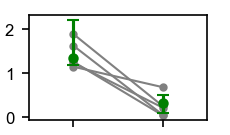

In [37]:
default()
widget()
arial()

# --- Figure settings ---
cm_to_inch = 1 / 2.54
fig_width_cm = 3.9
fig_height_cm = 2.3

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)

# --- Pool all vmax values across fish ---
vmax_control_all = []
vmax_viscosity_all = []

for summary in summary_vmax:
    vmax_control_all.extend(summary['vmax_control'])
    vmax_viscosity_all.extend(summary['vmax_viscosity'])

# --- Convert to arrays and filter ---
all_cont = np.array(vmax_control_all)
all_int = np.array(vmax_viscosity_all)
all_cont = all_cont[~np.isnan(all_cont)]
all_int = all_int[~np.isnan(all_int)]

# --- Compute medians and means ---
medians = [np.nanmedian(all_cont), np.nanmedian(all_int)]
means = [np.nanmean(all_cont), np.nanmean(all_int)]

# --- Compute IQRs ---
iqps = [np.nanquantile(all_cont, 0.75) - medians[0],
        np.nanquantile(all_int, 0.75) - medians[1]]
iqms = [medians[0] - np.nanquantile(all_cont, 0.25),
        medians[1] - np.nanquantile(all_int, 0.25)]

# --- Define positions and colors ---
positions = [0, 1]

# --- Per-fish paired gray lines ---
for summary in summary_vmax:
    y_control = summary['mean_control']
    y_visc = summary['mean_viscosity']
    plt.plot(0, y_control, '.', color='gray')
    plt.plot(1, y_visc, '.', color='gray')
    plt.plot([0, 1], [y_control, y_visc], color='gray', linewidth=1)

# --- Plot mean with asymmetric IQR error bars ---
iqps = [8.570780697308125, 1.8490519082278505]
plt.errorbar(positions, means, yerr=[iqms, iqps], fmt='o', color='green', capsize=3, markersize=4)

# --- Mann-Whitney U test ---
stat, pval = mannwhitneyu(all_cont, all_int, alternative='two-sided')
print(f"p-value: {pval:.3e}")

# --- Annotate significance ---
y_max = max(means[i] + iqps[i] for i in [0, 1]) * 1.1
#plt.plot([0, 1], [y_max, y_max], color='black')
#plt.text(0.5, y_max * 1.01,f"{'*' if pval < 0.05 else 'n.s.'}", ha='center', va='bottom', fontsize=14)

# --- Formatting ---
plt.xticks([0, 1], ['control', 'viscosity'])
plt.yticks([0, 10, 20], ['0', '1', '2'])  # cm/s
plt.ylabel('$v_\\mathrm{start}$ (cm/s)')
plt.xlim(-0.5, 1.5)
#plt.ylim(0, y_max * 1.2)

# --- Save ---
fig.savefig(str(FIGURES_DIR / "Fig_S13d_stat_vmax_control_viscosity.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S13d_stat_vmax_control_viscosity.pdf"), format="pdf", bbox_inches='tight', dpi=200)
plt.show()

In [80]:
means

[8.863190732092338, 3.0437626663375967]

In [68]:
8.166702482260433/2.9820490781489357

2.738621085112991

In [97]:
iqps

[13.570780697308125, 1.8490519082278505]